In [2]:
!pip install PyWavelets

In [3]:
import os
import numpy as np
from PIL import Image

import pywt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
import torchvision.transforms as T
from torchvision.datasets import ImageFolder
import torchvision.models as models
from torchsummary import summary


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


### Apply the 3-layer Wavelet packet transform on input images (on one image)

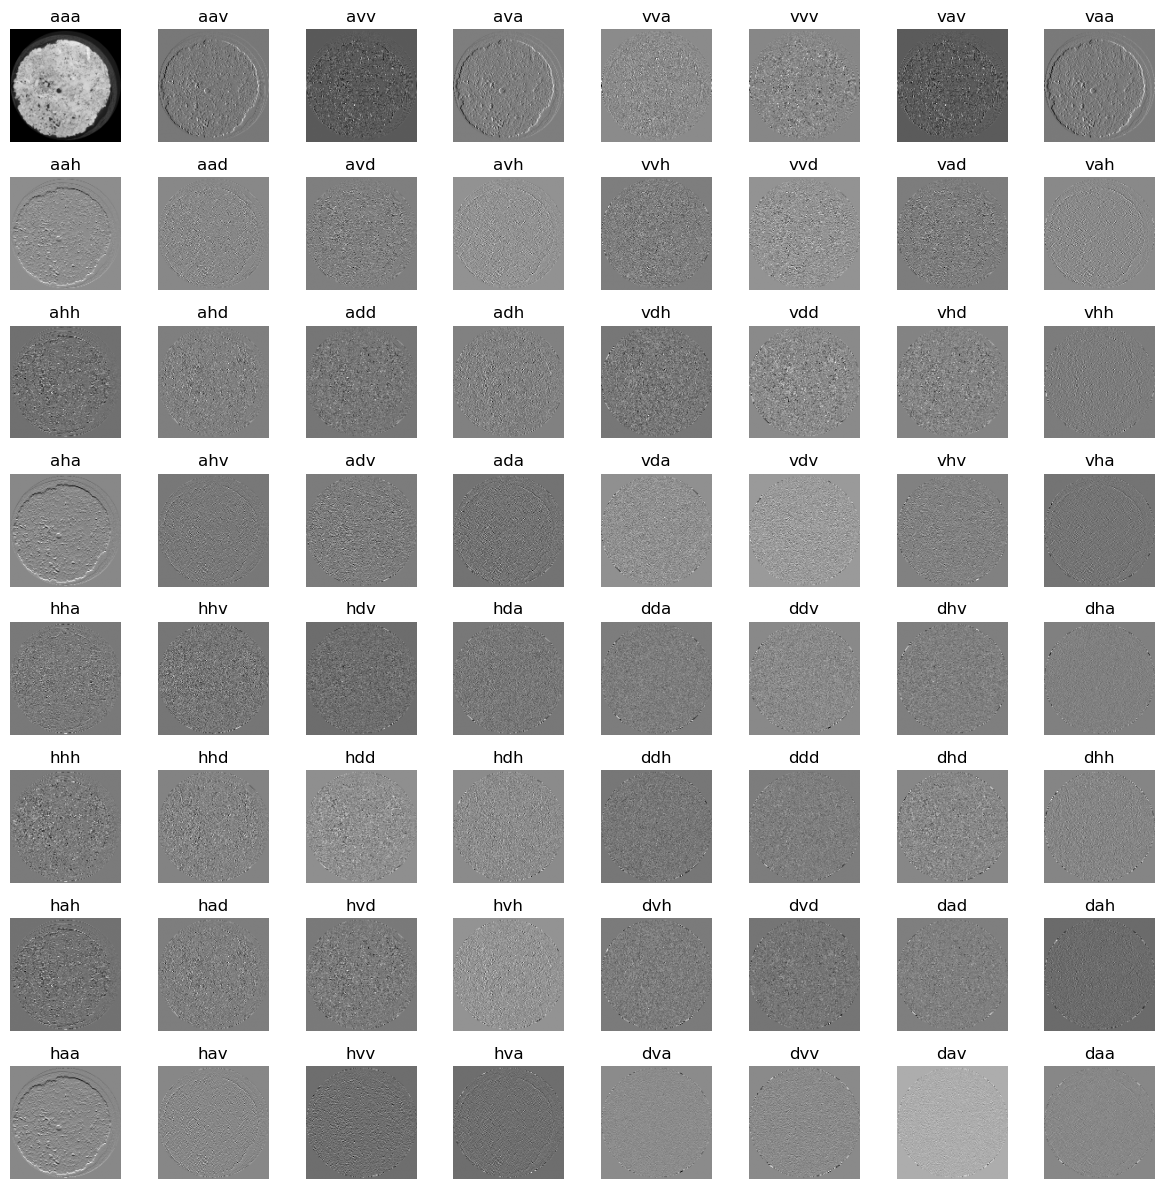

In [5]:
import pywt
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Load image
img = Image.open("/Users/amani.khalid/Desktop/SRP 2/data/tif_pages_cylinders/page_3.png").convert("L")  # grayscale for simplicity
img = np.array(img)

# Wavelet Packet Transform (2D)
wp = pywt.WaveletPacket2D(data=img, wavelet='haar', maxlevel=3)

#3-level wavelet packet transform 
nodes = wp.get_level(3, order='freq')

rows = len(nodes)
cols = len(nodes[0])

fig, axes = plt.subplots(rows, cols, figsize=(12, 12))

for i in range(rows):
    for j in range(cols):
        axes[i, j].imshow(nodes[i][j].data, cmap='gray')
        axes[i, j].set_title(nodes[i][j].path)
        axes[i, j].axis('off')

plt.tight_layout()
plt.show()


### Image processing (data)

In [7]:
import os
import random
from typing import Tuple, List
from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T

# use the same IMG_SIZE you used for WPT
IMG_SIZE = 448

# basic transforms for model input (WPT happens inside the model)
base_transform = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
])

#Training set augnemtation (new)

#Augementation of training set
train_transform = T.Compose([
    T.RandomResizedCrop(448, scale=(0.7, 1.0)),
    T.RandomHorizontalFlip(),
    T.RandomVerticalFlip(),
    T.RandomRotation(180),
])

val_transform = T.Compose([
    T.Resize(480),
    T.CenterCrop(448),
])


class PathImageDataset(Dataset):
    """
    Dataset from a list of (img_path, label_index) pairs.
    Returns (tensor_image, label).
    """
    def __init__(self, samples: List[Tuple[str, int]], classes: List[str], transform=None):
        self.samples = samples
        self.classes = classes
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        img = Image.open(img_path).convert("RGB")
        if self.transform is not None:
            img = self.transform(img)
        return img, label


def make_wpt_dataloaders(
    data_root,
    batch_size=8,
    val_ratio=0.1,
    test_ratio=0.1,
    C_keep=16,
    energy_max_samples=None,
    seed=42,
):
    """
    data_root: folder with class subfolders
    Returns:
        train_loader, val_loader, test_loader, class_names, selected_channels
    """
    assert os.path.isdir(data_root), f"{data_root} does not exist"

    # 1) Base dataset that returns (PIL_image, label)
    full_base = ImageFolder(root=data_root)  # no transform → returns raw PIL
    class_names = full_base.classes
    num_classes = len(class_names)
    print("Classes:", class_names)

    # 2) Split into train/val/test
    n_total = len(full_base)
    n_val = int(n_total * val_ratio)
    n_test = int(n_total * test_ratio)
    n_train = n_total - n_val - n_test

    g = torch.Generator().manual_seed(seed)
    train_base, val_base, test_base = random_split(full_base, [n_train, n_val, n_test], generator=g)

    print(f"Total images: {n_total}")
    print(f"Train: {len(train_base)}, Val: {len(val_base)}, Test: {len(test_base)}")

    # 3) Compute energy-based channel selection on training subset
    #    (train_base is a Subset, but still returns (PIL, label))
    selected_channels = select_top_channels(
        train_base,
        C_keep=C_keep,
        max_samples=energy_max_samples
    )

    # 4) Wrap each subset in WaveletPacketDataset

    train_ds = WaveletPacketDataset(train_base, selected_channels, transform=train_transform)
    val_ds = WaveletPacketDataset(val_base, selected_channels, transform=val_transform)
    test_ds = WaveletPacketDataset(test_base, selected_channels, transform=val_transform)


    # 5) DataLoaders
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,
                              num_workers=0, pin_memory=False)
    val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False,
                              num_workers=0, pin_memory=False)
    test_loader  = DataLoader(test_ds,  batch_size=batch_size, shuffle=False,
                              num_workers=0, pin_memory=False)

    return train_loader, val_loader, test_loader, class_names, selected_channels

### 2D Wavelet Packet Transform (3-level)

In [9]:
import pywt
import numpy as np
import torch
from PIL import Image
import torchvision.transforms as T

resize_tf = T.Resize((IMG_SIZE, IMG_SIZE))

resize_tf = T.Resize((IMG_SIZE, IMG_SIZE))

def wavelet_packet_haar_3level(img_pil: Image.Image) -> torch.Tensor:
    """
    Apply 3-level 2D Haar WPT and return tensor [64, H_sub, W_sub].
    For 448×448 input and level=3 → H_sub = W_sub = 56.
    """
    # 1) Resize and convert to grayscale
    img_pil = resize_tf(img_pil)
    img_gray = img_pil.convert("L")

    # 2) To numpy
    img_np = np.array(img_gray, dtype=np.float32)

    # 3) 3-level WPT
    wp = pywt.WaveletPacket2D(
        data=img_np,
        wavelet='haar',
        mode='symmetric',
        maxlevel=3
    )

    # 4) Get level 3 nodes as nested list (rows × cols)
    nodes_grid = wp.get_level(3, order='freq')  # nested list

    subbands = []
    for row in nodes_grid:
        for node in row:
            subbands.append(node.data.astype(np.float32))  # each [H_sub, W_sub]

    # 5) Stack into [64, H_sub, W_sub]
    W = np.stack(subbands, axis=0)

    # 6) Convert to torch tensor
    return torch.from_numpy(W)  # [64, H_sub, W_sub], float32

### Selection (Energy-based)

In [11]:
def compute_channel_energy_wpt(train_base_dataset, max_samples=None):
    """
    train_base_dataset: dataset that returns (PIL_image, label)
    Returns: np.array of shape (64,) with avg energy per channel.
    """
    sum_energy = None
    total_pixels = 0

    n_samples = len(train_base_dataset) if max_samples is None else min(len(train_base_dataset), max_samples)

    for idx in range(n_samples):
        img, _ = train_base_dataset[idx]  # PIL image
        W = wavelet_packet_haar_3level(img)  # [64, H_sub, W_sub]

        C, H, W_sub = W.shape
        energy = (W ** 2).sum(dim=(1, 2))  # [64]

        if sum_energy is None:
            sum_energy = energy
        else:
            sum_energy += energy

        total_pixels += H * W_sub

    avg_energy = (sum_energy / float(total_pixels)).numpy()
    return avg_energy  # shape (64,)


def select_top_channels(train_base_dataset, C_keep=16, max_samples=None):
    """
    Convenience wrapper: compute avg energies and return list of top-K channel indices.
    """
    avg_energy = compute_channel_energy_wpt(train_base_dataset, max_samples=max_samples)
    top_idx = np.argsort(-avg_energy)[:C_keep]       # sort descending
    selected_channels = sorted(top_idx.tolist())     # sort indices to keep order stable
    print("Selected channels:", selected_channels)
    return selected_channels

### Selected Wavelet (subbands - with highest energies)

In [13]:
#Data set that returns only selected channels

class WaveletPacketDataset(Dataset):
    """
    Wraps a base dataset that returns (PIL_image, label).
    For each item, applies 3-level Haar WPT and keeps only selected channels.
    Returns (W_sel, label) where W_sel: [C_keep, H_sub, W_sub].
    """
    def __init__(self, base_dataset, selected_channels, transform=None):
        self.base = base_dataset
        self.selected_channels = selected_channels
        self.transform = transform

    def __len__(self):
        return len(self.base)

    def __getitem__(self, idx):
        img, label = self.base[idx]   # PIL image

        if self.transform is not None:
            img = self.transform(img)  # ← augmentation happens here

        W = wavelet_packet_haar_3level(img)
        W_sel = W[self.selected_channels, :, :]
        return W_sel, label


### The CNN Structrue (Modified ResNet50)

In [15]:
import torch
import torch.nn as nn
import torchvision.models as models
#Here we keep ResNet’s structure but change conv1 to accept in_channels = C_keep.
class WPTResNet50(nn.Module):
    def __init__(self, num_classes, in_channels):
        super().__init__()
        base = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)

        # Save original conv1 for weight reuse
        old_conv = base.conv1

        # New conv1 with in_channels = number of wavelet channels
        base.conv1 = nn.Conv2d(
            in_channels,
            old_conv.out_channels,
            kernel_size=old_conv.kernel_size,
            stride=old_conv.stride,
            padding=old_conv.padding,
            bias=False,
        )

        # Initialize new conv1 weights (simple strategy)
        with torch.no_grad():
            if in_channels == 1:
                # Average original RGB weights
                base.conv1.weight[:] = old_conv.weight.mean(dim=1, keepdim=True)
            elif in_channels == 3:
                # Directly copy
                base.conv1.weight.copy_(old_conv.weight)
            else:
                # For >3 channels: copy RGB and average for remaining
                base.conv1.weight[:, :3, :, :] = old_conv.weight
                if in_channels > 3:
                    extra = in_channels - 3
                    mean_extra = old_conv.weight.mean(dim=1, keepdim=True)
                    base.conv1.weight[:, 3:3+extra, :, :] = mean_extra.repeat(1, extra, 1, 1)

        # Replace classifier head for your number of classes
        in_feats = base.fc.in_features
        base.fc = nn.Linear(in_feats, num_classes)

        self.model = base

    def forward(self, x):
        # x: [B, C_keep, H_sub, W_sub], e.g. [B,16,56,56]
        return self.model(x)

### Train and validation loop

In [17]:
def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for W_sel, labels in loader:  # W_sel: [B, C_keep, H_sub, W_sub]
        W_sel = W_sel.to(device).float()
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(W_sel)  # [B, num_classes]
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        _, preds = outputs.max(1)
        correct += preds.eq(labels).sum().item()
        total += labels.size(0)

    return running_loss / total, (correct / total)*100


def eval_one_epoch(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for W_sel, labels in loader:
            W_sel = W_sel.to(device).float()
            labels = labels.to(device)

            outputs = model(W_sel)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * labels.size(0)
            _, preds = outputs.max(1)
            correct += preds.eq(labels).sum().item()
            total += labels.size(0)

    return running_loss / total, (correct / total)*100

### Train the model 

In [19]:
data_root = '/Users/amani.khalid/Desktop/SRP 2/Rock Data/train'  # update this

batch_size = 8
C_keep = 32          # number of most-energetic subbands to keep
num_epochs = 50
energy_max_samples = None  # or e.g. 200 if you want faster energy estimation

train_loader, val_loader, test_loader, class_names, selected_channels = make_wpt_dataloaders(
    data_root=data_root,
    batch_size=batch_size,
    val_ratio=0.1,
    test_ratio=0.1,
    C_keep=C_keep,
    energy_max_samples=energy_max_samples,
    seed=42,
)

num_classes = len(class_names)

train_acc_list = []
val_acc_list = []

train_loss_list = []
val_loss_list = []


model = WPTResNet50(num_classes=num_classes, in_channels=len(selected_channels)).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)

for epoch in range(num_epochs):
    train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion, device)
    val_loss, val_acc = eval_one_epoch(model, val_loader, criterion, device)

    train_acc_list.append(train_acc)
    val_acc_list.append(val_acc)
    train_loss_list.append(train_loss)
    val_loss_list.append(val_loss)

    print(f"Epoch {epoch+1}/{num_epochs}: "
          f"Train loss: {train_loss:.4f}, acc: {train_acc:.2f}%  | "
          f"Val loss {val_loss:.4f}, acc: {val_acc:.2f}%")



Classes: ['Basalt', 'Class 1', 'Class 2', 'Class 3', 'Clay', 'Conglomerate', 'Diatomite', 'Shale-(Mudstone)', 'Siliceous-sinter', 'chert', 'gypsum', 'olivine-basalt']
Total images: 3864
Train: 3092, Val: 386, Test: 386
Selected channels: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 24, 25, 26, 27, 32, 33, 40, 41, 48, 49, 56, 57]
Epoch 1/50: Train loss: 2.1206, acc: 23.35%  | Val loss 2.0058, acc: 34.20%
Epoch 2/50: Train loss: 1.7686, acc: 36.93%  | Val loss 1.7467, acc: 44.56%
Epoch 3/50: Train loss: 1.6164, acc: 42.14%  | Val loss 1.7973, acc: 51.30%
Epoch 4/50: Train loss: 1.4964, acc: 46.47%  | Val loss 1.3730, acc: 52.85%
Epoch 5/50: Train loss: 1.4239, acc: 49.35%  | Val loss 1.4044, acc: 53.63%
Epoch 6/50: Train loss: 1.3672, acc: 51.68%  | Val loss 1.1817, acc: 59.33%
Epoch 7/50: Train loss: 1.2729, acc: 55.30%  | Val loss 1.1520, acc: 61.66%
Epoch 8/50: Train loss: 1.2375, acc: 56.24%  | Val loss 1.1603, acc: 63.47%
Epoch 9/50: Train loss: 1.1547, acc

In [20]:
summary(model, input_size=( 32, 224, 224), device=str(device))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 64, 112, 112]         100,352
       BatchNorm2d-2         [-1, 64, 112, 112]             128
              ReLU-3         [-1, 64, 112, 112]               0
         MaxPool2d-4           [-1, 64, 56, 56]               0
            Conv2d-5           [-1, 64, 56, 56]           4,096
       BatchNorm2d-6           [-1, 64, 56, 56]             128
              ReLU-7           [-1, 64, 56, 56]               0
            Conv2d-8           [-1, 64, 56, 56]          36,864
       BatchNorm2d-9           [-1, 64, 56, 56]             128
             ReLU-10           [-1, 64, 56, 56]               0
           Conv2d-11          [-1, 256, 56, 56]          16,384
      BatchNorm2d-12          [-1, 256, 56, 56]             512
           Conv2d-13          [-1, 256, 56, 56]          16,384
      BatchNorm2d-14          [-1, 256,

 Average accuracy on validation set is 79.72020725388602


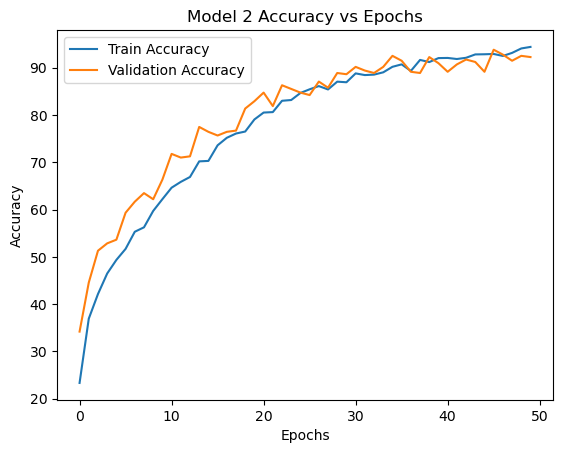

In [21]:
import matplotlib.pyplot as plt

avg_val_acc = sum(val_acc_list)/50
print(f' Average accuracy on validation set is {avg_val_acc}')

plt.title('Model 2 Accuracy vs Epochs')
plt.plot(train_acc_list, label='Train Accuracy')
plt.plot(val_acc_list, label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [22]:
# Final test evaluation
test_loss, test_acc = eval_one_epoch(model, test_loader, criterion, device)
print(f"Test loss: {test_loss:.4f}, Test acc: {test_acc:.4f}%")

Test loss: 0.2142, Test acc: 93.0052%


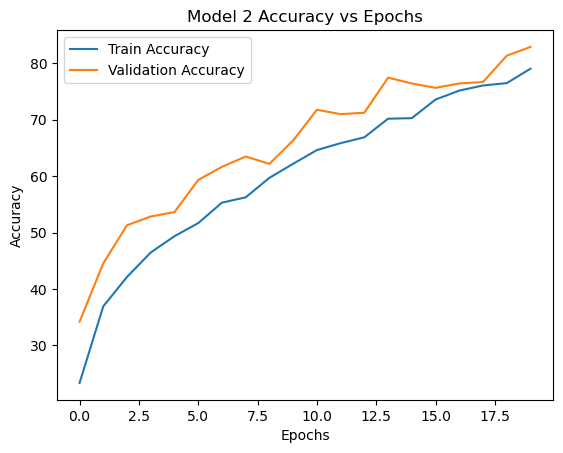

In [23]:
avg_val_acc = sum(val_acc_list)/50

plt.title('Model 2 Accuracy vs Epochs')
plt.plot(train_acc_list[0:20], label='Train Accuracy')
plt.plot(val_acc_list[0:20], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [45]:
import torch

# after training finishes

torch.save({
    "model_state": model.state_dict(),
    "selected_channels": selected_channels,
    "class_names": class_names
}, "waveletpacket_resNet50_rockandReal(with aug_new_2).pth")

[[37  0  0  0  1  0  0  0  0  0  0  1]
 [ 0  9  2  0  0  0  0  0  0  0  0  0]
 [ 0  0  4  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  1  0  0  0  0  0  0  0  0]
 [ 2  0  0  0 35  0  0  0  0  0  0  0]
 [ 1  0  0  0  0 39  1  0  2  0  0  1]
 [ 0  0  0  0  3  0 45  1  0  2  0  0]
 [ 0  0  0  0  2  1  1 42  0  0  0  0]
 [ 1  0  0  0  1  0  0  0 31  0  0  0]
 [ 1  0  0  0  1  0  0  0  0 47  0  0]
 [ 0  0  0  0  0  0  0  0  0  1 35  0]
 [ 0  0  0  0  1  1  0  0  2  0  0 31]]


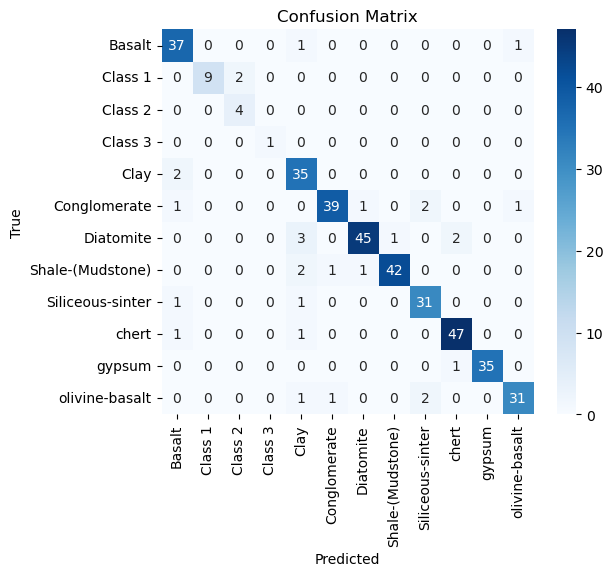

In [25]:
import torch
from sklearn.metrics import confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for x, y in val_loader:   # or test_loader
        x = x.to(device)
        y = y.to(device)

        outputs = model(x)
        preds = torch.argmax(outputs, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y.cpu().numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

cm = confusion_matrix(all_labels, all_preds)
print(cm)


plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

In [26]:
from sklearn.metrics import classification_report

print(classification_report(
    all_labels,
    all_preds,
    target_names=class_names
))

                  precision    recall  f1-score   support

          Basalt       0.88      0.95      0.91        39
         Class 1       1.00      0.82      0.90        11
         Class 2       0.67      1.00      0.80         4
         Class 3       1.00      1.00      1.00         1
            Clay       0.80      0.95      0.86        37
    Conglomerate       0.95      0.89      0.92        44
       Diatomite       0.96      0.88      0.92        51
Shale-(Mudstone)       0.98      0.91      0.94        46
Siliceous-sinter       0.89      0.94      0.91        33
           chert       0.94      0.96      0.95        49
          gypsum       1.00      0.97      0.99        36
  olivine-basalt       0.94      0.89      0.91        35

        accuracy                           0.92       386
       macro avg       0.92      0.93      0.92       386
    weighted avg       0.93      0.92      0.92       386

